# 06 · Treino do juiz (CRISP-DM: modelagem e avaliação)

O juiz julgava as fotos com o **CLIP sem treino** (zero-shot: compara a foto com frases) e o **Qwen2.5-VL** (IA de visão).
Ninguém sabia quanto eles acertavam: o jogo não guarda as fotos e não havia fotos com a resposta certa.

Aqui o CLIP ganha uma **camada treinada** (`src/treino_juiz.py`) e a junção com o Qwen passa a ser decidida com dados.

- **Fotos:** 3.898 do [Open Images V7](https://storage.googleapis.com/openimages/web/index.html) (imagens CC BY 2.0; créditos em `fotos.csv`),
  sem rostos de pessoas: os 5 temas, "nenhum" (sapato, cadeira, celular, prédio...), brinquedos e desenhos/estátuas.
- **Falsas geradas** (`src/falsas.py`): cada foto também vira "na tela" (celular/monitor/TV, moiré, reflexo) e "impressa".
- **Versões de celular:** recorte, giro, luz, borrão e JPEG, para parecer foto tirada andando.
- **Separação pela foto original:** 70% treino, 15% validação (escolhas), 15% teste (só para medir, nunca visto no treino).

Para refazer: `scripts/baixar_fotos_treino.py` e depois `scripts/treinar_juiz.py --com-ia 500` (veja o topo de cada um).

In [1]:
import json, os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
m = json.loads((RAIZ / "modelos" / "juiz_clip_metricas.json").read_text(encoding="utf-8"))
DADOS = Path(os.environ.get("WISHLENS_TREINO", r"\\wsl.localhost\Ubuntu\opt\wishlens-treino"))
tem_dados = (DADOS / "previsoes_teste.csv").exists()
print(f"{m['fotos']} fotos, {m['exemplos']} exemplos; por parte: {m['por_parte']}")
print("escolhido na validação:", {k: (round(v, 3) if isinstance(v, float) else v) for k, v in m['treino'].items() if k != 'acerto_tema_por_alfa'})

3898 fotos, 14192 exemplos; por parte: {'teste': 2078, 'treino': 10016, 'validacao': 2098}
escolhido na validação: {'C_tema': 3.0, 'C_falsa': 10.0, 'alfa': 0.9, 'beta': 0.9, 'limiar': 0.749, 'limiar_ia': 0.6, 'tema_da_ia': False}


## O que é acertar

Para cada foto do teste o jogo deveria: **aceitar no tema certo** se for foto real de um tema; **recusar** se for
"nenhum" ou falsa (tela, impressa, brinquedo, desenho). O erro que mais irrita o jogador é **recusar uma foto real**.

In [2]:
NOMES = {"clip_zero_shot": "CLIP sem treino", "clip_treinado": "CLIP treinado"}
pd.DataFrame(m["teste"]).T.rename(index=NOMES)[["acerto_geral", "foto_real_recusada", "falsa_aceita", "tema_certo_nas_reais", "n"]].round(3)

,acerto_geral,foto_real_recusada,falsa_aceita,tema_certo_nas_reais,n
CLIP sem treino,0.727,0.221,0.231,0.846,2078.0
CLIP treinado,0.873,0.036,0.170,0.965,2078.0


## Com o Qwen (amostra de 500 fotos de validação + teste, julgadas na placa de vídeo)

- **Hoje** = a regra que estava no servidor: a IA decide e o CLIP sem treino pode vetar.
- **Junção nova** = o CLIP treinado decide o tema; a IA só derruba o "é real" quando a chance de falsa do CLIP passa de um limite
  (escolhido na validação, com no máximo 5% de fotos reais recusadas).

In [3]:
REGRAS = {"ia+clip_zero_shot": "Hoje: IA + CLIP sem treino", "ia_sozinha": "IA sozinha",
          "clip_zero_shot_sozinho": "CLIP sem treino sozinho", "clip_treinado_sozinho": "CLIP treinado sozinho",
          "ia+clip_treinado": "IA + CLIP treinado (regra antiga)", "ia+clip_juncao_nova": "Junção nova (no juiz)"}
teste_ia = pd.DataFrame(m["com_ia"]["teste"]).T.rename(index=REGRAS)
teste_ia[["acerto_geral", "foto_real_recusada", "falsa_aceita", "tema_certo_nas_reais", "n"]].round(3).sort_values("acerto_geral")

,acerto_geral,foto_real_recusada,falsa_aceita,tema_certo_nas_reais,n
CLIP sem treino sozinho,0.720,0.220,0.250,0.859,243.0
IA sozinha,0.770,0.308,0.151,0.910,243.0
Hoje: IA + CLIP sem treino,0.794,0.407,0.125,0.910,243.0
IA + CLIP treinado (regra antiga),0.819,0.341,0.086,0.910,243.0
Junção nova (no juiz),0.868,0.033,0.171,0.962,243.0
CLIP treinado sozinho,0.868,0.022,0.178,0.962,243.0


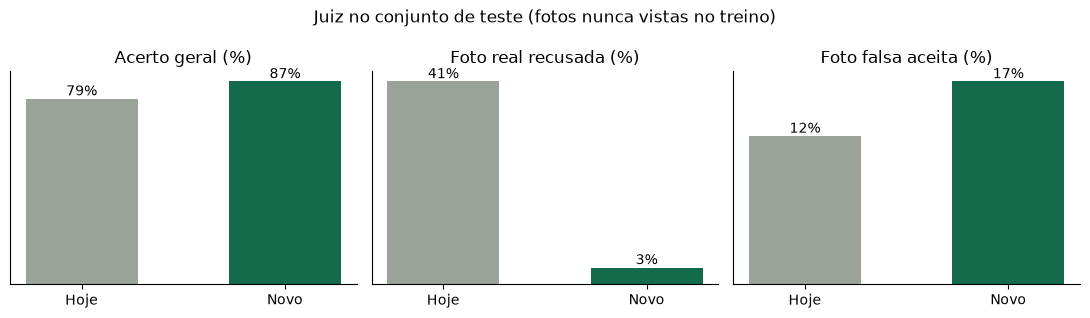

In [4]:
linhas = ["Hoje: IA + CLIP sem treino", "Junção nova (no juiz)"]
d = teste_ia.loc[linhas, ["acerto_geral", "foto_real_recusada", "falsa_aceita"]] * 100
fig, eixos = plt.subplots(1, 3, figsize=(11, 3.2), sharey=False)
for eixo, (col, titulo) in zip(eixos, [("acerto_geral", "Acerto geral (%)"), ("foto_real_recusada", "Foto real recusada (%)"),
                                       ("falsa_aceita", "Foto falsa aceita (%)")]):
    barras = eixo.bar(["Hoje", "Novo"], d[col], color=["#9aa39a", "#136B4C"], width=0.55)
    eixo.bar_label(barras, fmt="%.0f%%")
    eixo.set_title(titulo)
    eixo.spines[["top", "right"]].set_visible(False)
    eixo.set_yticks([])
fig.suptitle("Juiz no conjunto de teste (fotos nunca vistas no treino)")
plt.tight_layout()

## Por tipo de foto (teste completo, só CLIP)

In [5]:
if tem_dados:
    p = pd.read_csv(DADOS / "previsoes_teste.csv")
    p["tipo"] = p["grupo"].where(p["grupo"].isin(["brinquedo", "desenho"]), p["variante"])

    def certo(tema, real):
        """Aceitou no tema certo a foto real de tema; recusou nenhum e falsas."""
        tema = tema.fillna("nenhum")
        aceita = real.astype(bool) & (tema != "nenhum")
        deveria = p["real"] & (p["tema"] != "nenhum")
        return (deveria & aceita & (tema == p["tema"])) | (~deveria & ~aceita)
    p["zero_shot"] = certo(p["zs_tema"], p["zs_real"])
    p["treinado"] = certo(p["tr_tema"], p["tr_real"])
    display(p.groupby("tipo")[["zero_shot", "treinado"]].mean().round(2).assign(n=p.groupby("tipo").size()))
else:
    print("Sem a pasta de dados do treino: veja as tabelas acima.")

,zero_shot,treinado,n
tipo,,,
brinquedo,0.84,0.89,122
celular,0.62,0.91,453
desenho,0.69,0.45,144
impressa,0.74,0.87,453
original,0.73,0.95,453
tela,0.80,0.90,453


## Tema: matriz de confusão do CLIP treinado (fotos reais do teste)

In [6]:
if tem_dados:
    reais = p[p["real"]]
    display(pd.crosstab(reais["tema"], reais["tr_tema"], rownames=["verdade"], colnames=["CLIP treinado"]))

CLIP treinado,carros,comidas,nenhum,pecas,pets,plantas
verdade,,,,,,
carros,118,0,0,0,0,0
comidas,0,138,0,0,0,0
nenhum,2,1,173,6,0,2
pecas,0,0,6,138,0,0
pets,0,0,0,0,168,2
plantas,0,4,7,0,6,135


## Alguns erros do CLIP treinado

,id,autor,licenca,url
1071,b7d9a41f695b0383,Mike Lizzi,https://creativecommons.org/licenses/by/2.0/,https://farm4.staticflickr.com/6068/6161942926...
199,b7a75cea3caf3135,Vladimir Fedotov,https://creativecommons.org/licenses/by/2.0/,https://farm6.staticflickr.com/3220/4607974443...
1537,3d2580d59f499cce,D@LY3D,https://creativecommons.org/licenses/by/2.0/,https://c7.staticflickr.com/4/3747/9718047231_...
1860,5bd094011dba0dbc,Gennaro Visciano,https://creativecommons.org/licenses/by/2.0/,https://c5.staticflickr.com/1/14/18366123_4507...
506,e87af05dacf62657,Ezra S F,https://creativecommons.org/licenses/by/2.0/,https://farm8.staticflickr.com/3567/3485745805...
2068,dba4fe6a809fc7c2,Mathieu Plourde,https://creativecommons.org/licenses/by/2.0/,https://farm3.staticflickr.com/3077/2825462901...
2008,836efa86a5231567,chunkysalsa,https://creativecommons.org/licenses/by/2.0/,https://farm8.staticflickr.com/8301/7883504404...
1584,5a010c1bb4062043,E-Plus Gruppe Fotostream,https://creativecommons.org/licenses/by/2.0/,https://farm4.staticflickr.com/8297/7843418518...


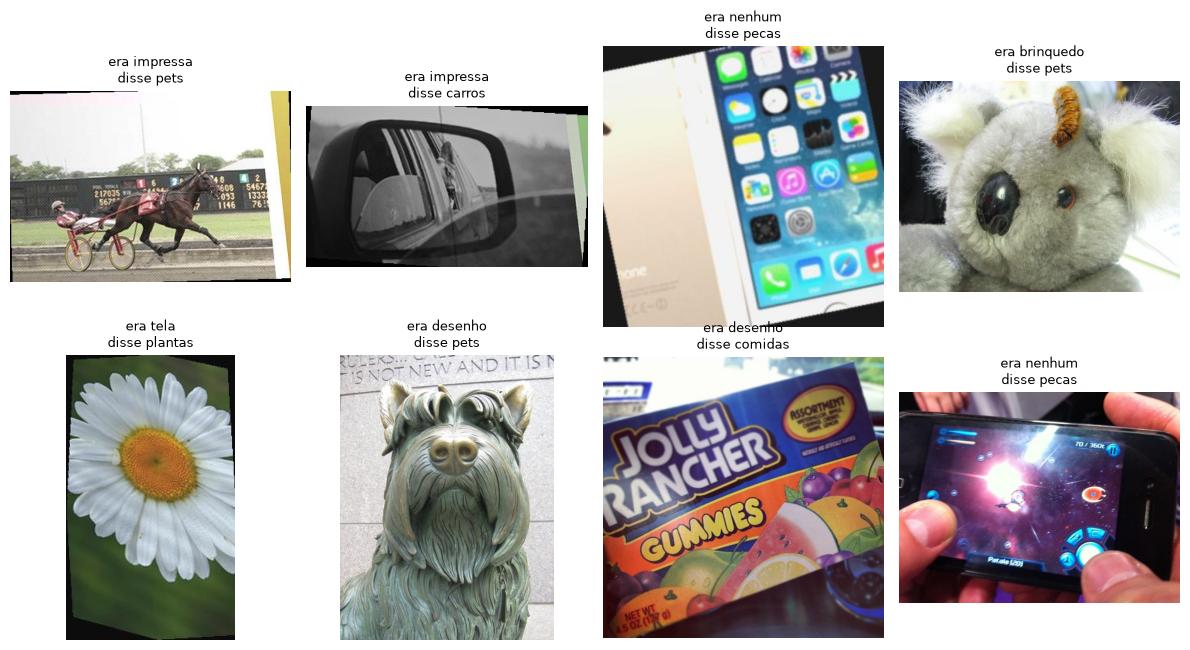

In [7]:
if tem_dados:
    from PIL import Image
    import sys
    sys.path.insert(0, str(RAIZ))
    from src.treino_juiz import gerar
    erros = p[~p["treinado"]].sample(8, random_state=1)
    fig, eixos = plt.subplots(2, 4, figsize=(12, 6.5))
    for eixo, r in zip(eixos.flat, erros.itertuples()):
        eixo.imshow(gerar(Image.open(DADOS / "fotos" / f"{r.id}.jpg"), r.variante, r.id))
        disse = r.tr_tema + ("" if r.tr_real else " (falsa)")
        eixo.set_title(f"era {r.tema if r.real else r.tipo}\ndisse {disse}", fontsize=9)
        eixo.axis("off")
    plt.tight_layout()
    display(erros[["id", "autor", "licenca", "url"]])

## Conclusões

- **O CLIP treinado é a maior melhora.** No teste completo, o acerto geral passou de 73% para 87%. As fotos reais recusadas
  por engano caíram de 22% para 4% e o tema certo subiu de 85% para 97%.
- **O Qwen recusava fotos reais demais** (~1 em cada 3 nesta amostra), principalmente fotos com aparência profissional.
  Por isso, na junção nova, ele só derruba uma foto quando o CLIP treinado também desconfia.
- **Junção nova × hoje** (amostra com a IA, teste): o acerto geral passou de 79% para 87% e a foto real recusada de 41% para 3%.
  Em troca, um pouco mais de falsas passa (de 13% para 17%). No teste, a junção nova empatou com o CLIP treinado sozinho
  (na validação ficou 2 pontos acima). O Qwen continua no juiz porque dá o achado detalhado (modelo do carro, espécie).
  Ele também é uma segunda opinião contra falsas que o CLIP deixa passar.
- **Ponto fraco: desenhos, pinturas e estátuas.** Eles são poucos no treino e o CLIP treinado acerta menos que antes (cerca de 45% contra 69%).

**O que não foi medido:**
- fotos tiradas com o celular de verdade (as do banco são do Flickr e as "de celular" são simuladas);
- imagens geradas por IA;
- telas e impressões reais: as do treino são geradas por programa, então o acerto nelas pode ser otimista.

O próximo passo é juntar fotos da turma marcadas com a resposta certa e treinar de novo.